In [9]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from scipy.linalg import null_space
from gauge_arbitrage import vf
from gauge_arbitrage import time_series

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
import gauge_arbitrage; print(gauge_arbitrage.__path__)

_NamespacePath(['/Users/raymondqin/Documents/research/Gauge_Arbitrage/src/gauge_arbitrage'])


# Day 4
I am extremely busy this week so I cannot do much for the project, so the first three days were skipped. This week, we are focused on testing the V&F algorithm. Today, I implemented the calculation for $D$ (D_direct, D_formula):
$$D=E[h_th_{t+1}]=J^T(\Gamma_1+\mu\mu^T)J$$
and the sum over the $k$ calm directions (D_total):
$$D=\sum_A(J^A)^T(\Gamma_1+\mu\mu^T)J^A$$

In [10]:
B=vf.vf_series(200, 200)
rng=np.random.default_rng(seed=0)

In [4]:
B.horizon

200

In [9]:
X.shape

(201, 21)

In [11]:
vf.calc_R(X).shape

(200, 21)

In [12]:
X[:, 0]

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

Text(0.5, 1.0, 'Simulation with 20 log-normal random walks (compare to V&F)')

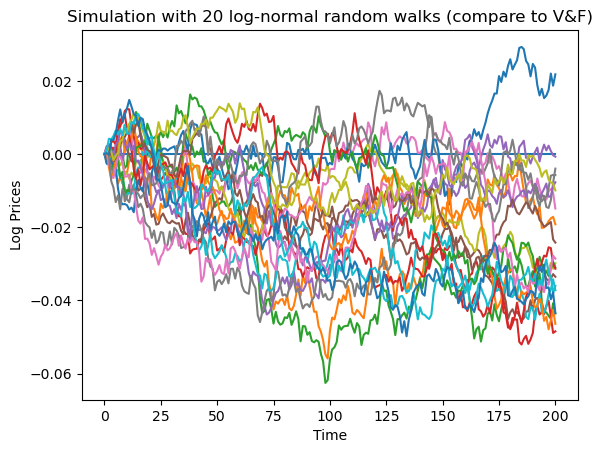

In [17]:
#test if the new package works (exact same code as 10_19.ipynb, but vf.X_mu_43)
beta_a=rng.uniform(low=-0.0001, high=0.0001, size=(18))                                        #Randomly generate values for beta
sigma=np.insert(rng.uniform(low=-0.001, high=0.001, size=(20, 18)),0,  np.zeros(18), axis=0)   #Randomly generate values for sigma
alpha_A=rng.uniform(low=-0.0001, high=0.0001, size=(2))                                        #Randomly generate values for alpha_A
Z=rng.standard_normal((200, 18))                #Randomly generate values for Brownian motions (only 18 independent Brownian motions)
X=B.X_mu_43(sigma, beta_a, alpha_A, 1, Z)       #Create the time series according to Eq. (106)

#Compare to V&F Figure 1
fig_1, ax_1=plt.subplots(1,1)
rng2=np.random.default_rng()

#plot 20 random walks
for i in range(21):
    ax_1.plot(B.times, np.log(X[:, i]))
ax_1.set_xlabel('Time')
ax_1.set_ylabel('Log Prices')
ax_1.set_title('Simulation with 20 log-normal random walks (compare to V&F)')

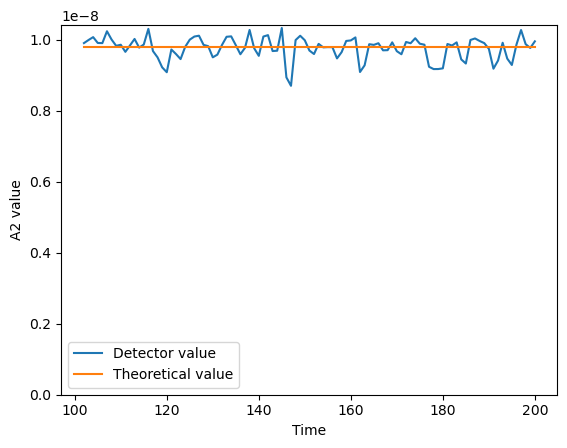

In [18]:
arr0=vf.run_estimator(X, k=2)
arr=arr0['A2'] # Run the detector
A2_values=arr[~np.isnan(arr)] #Remove nan values (window)

#This plot should match V&F figure 2
fig, ax=plt.subplots(1,1)
ax.plot(B.times[102:], A2_values, label='Detector value')
ax.plot(B.times[102:], np.zeros(99)+(alpha_A@alpha_A), label='Theoretical value')
ax.set_ylim(0)
ax.set_xlabel('Time')
ax.set_ylabel('A2 value')
ax.legend()

In [8]:
J_true

array([[-0.67225224,  0.38267826],
       [ 0.19406131, -0.1883428 ],
       [-0.03706477,  0.00874224],
       [ 0.19370239,  0.19531299],
       [ 0.27083178, -0.08641633],
       [-0.01050999, -0.10884564],
       [-0.06635612,  0.03725934],
       [ 0.08886108,  0.11289695],
       [ 0.03886426, -0.06837804],
       [ 0.12658104,  0.21358667],
       [-0.05245912, -0.36309861],
       [-0.20672742,  0.02519399],
       [ 0.17791817,  0.02689302],
       [ 0.01759933,  0.08993986],
       [ 0.24653142,  0.2082897 ],
       [-0.31308176,  0.06476795],
       [-0.1099473 , -0.16378354],
       [-0.19704758, -0.64981543],
       [ 0.1255002 , -0.03088357],
       [ 0.24774097,  0.23064283],
       [-0.06274565,  0.06336016]])

In [19]:
############################################################
#NEW CODE STARTS HERE
#Calculate D and compare it to the theoretical detector value
R=vf.calc_R(X)
J_true=vf.calc_J(sigma) #Actual values of J (Fixed J)
D_value=vf.D_total(R, J_true)
print(f"Calculated Value of D: {D_value}")
print(f"Theoretical Detector Value: {(alpha_A@alpha_A)}")

Calculated Value of D: 1.0223141445676217e-08
Theoretical Detector Value: 9.777943041086855e-09


In [8]:
############################################################
#Old functions as a record
def calc_R(X):
    return np.diff(np.log(X), axis=0)

#Left side calculation (E[h_th_t+1]) (Use this to verify)
def D_direct(R, J):
    h = R @ J                      # (T,)  h_t = J' r_t
    prod = h[:-1] * h[1:]          # h_t * h_{t+1}, t = 0 .. T-2
    se = prod.std(ddof=1) / np.sqrt(len(prod))   # standard error of the mean
    return prod.mean(), se

def moments(R):
    T, N = R.shape
    mu = R.mean(axis=0)                       # (N,)
    Rc = R - mu                               # centred returns
    Gamma0 = Rc.T @ Rc / T                    # Cov(r_t, r_t)
    Gamma1 = Rc[1:].T @ Rc[:-1] / (T - 1)     # Gamma1[i,j] = Cov(r_{i,t+1}, r_{j,t})
    return mu, Gamma0, Gamma1

#Right side (J^T(Gamma_1+mumu^T)J) (USE THIS ONE)
def D_formula(R, J):
    mu, _, Gamma1 = moments(R)
    drift_part = (J @ mu) ** 2                # (J' mu)^2
    autocov_part = J @ Gamma1 @ J             # J' Gamma_1 J
    return drift_part + autocov_part, drift_part, autocov_part

def split_autocov(Gamma1, J):
    """J' Gamma_1 J = own-autocorrelation part + cross-lag part."""
    own = np.sum(J ** 2 * np.diag(Gamma1))
    cross = J @ Gamma1 @ J - own
    return own, cross

#calculate the total D (USE THIS TO COMPARE AGAINST DETECTOR VALUE)
def D_total(R, J):
    return sum(D_formula(R, J_A)[0] for J_A in J.T)

In [119]:
temp=[]
for i in range(10000):
    arr1=np.linspace(1, 14, 14)
    rng.shuffle(arr1)
    temp1=0
    for j in range(12):
        if arr1[j]<arr1[j+1] and arr1[j+2]<arr1[j+1]:
            temp1+=1
    if arr1[0]>arr1[1]:
        temp1+=1
    if arr1[12]<arr1[13]:
        temp1+=1
    temp.append(temp1)

In [109]:
print(arr1)

[13.  5.  2.  8. 10.  6.  7.  1. 11.  4.  3.  9. 12. 14.]


In [120]:
np.array(temp).mean()

4.997